# Módulo 47: Medidas y KPIs

Autor: Juliho Castillo Colmenares

> Lección complementaria del ejercicio de este módulo: [enunciado](m47-medidas-y-kpis-guia.ipynb) y [solución](m47-medidas-y-kpis-solucion.ipynb). No es una tarea entregada del programa.

Sumar una columna es fácil. Pero las preguntas de negocio rara vez son una suma: "¿cuánto crecimos frente al mismo mes del año pasado?", "¿qué parte del total aporta cada país?", "¿cuánto llevamos vendido en el año?". Para responderlas hacen falta **medidas**: cálculos que agregan los datos respetando los filtros del tablero. En una herramienta de BI se escriben en un lenguaje de fórmulas propio; aquí son consultas SQL en DuckDB y funciones de Python, y las ideas de fondo son las mismas. Esta lección las recorre con las ventas de la práctica (1 499 000 filas de 2019 a 2021).

1. Medidas y columnas calculadas
2. El contexto de filtro: argumentos y `WHERE`
3. Suma de productos frente a producto de sumas
4. Fijar y quitar filtros
5. División segura y variables
6. La tabla de calendario
7. Inteligencia de tiempo
8. Variación mensual y anual
9. Las medidas en una app
10. Errores frecuentes
11. Ejercicio

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio

pio.renderers.default = "png"
pio.defaults.default_width = 900
pio.defaults.default_height = 450

sys.path.insert(0, str(Path("../practica-ventas").resolve()))
import ventas as practica

con = practica.conectar()

def ver(tabla, porcentajes=()):
    # Separador de miles con espacio, porcentajes y celdas vacías en blanco
    sin_formato = {"anio", "mes", "trimestre"}
    formatos = {}
    for columna in tabla.select_dtypes("number").columns:
        if columna in porcentajes:
            formatos[columna] = lambda v: "" if pd.isna(v) else f"{v:.2%}"
        elif columna not in sin_formato:
            valores = tabla[columna].dropna()
            decimales = 0 if (valores == valores.round()).all() else 2
            formatos[columna] = lambda v, d=decimales: "" if pd.isna(v) else f"{v:,.{d}f}".replace(",", " ")
    return tabla.style.format(formatos).hide(axis="index")

La función `ver` solo da formato a las tablas (miles separados con espacio, porcentajes y celdas vacías en blanco); no cambia los datos.

## 1. Medidas y columnas calculadas

Hay dos tipos de cálculo, y la diferencia importa:

| | Columna calculada | Medida |
| --- | --- | --- |
| Se escribe como | Una expresión fila a fila: `cantidad * precio AS importe` en un `SELECT` o una vista; `ventas["importe"] = ...` en pandas | Una función que **agrega**: `sum(importe)` dentro de una consulta con `WHERE` y `GROUP BY` |
| Se calcula | Una vez por fila | Una vez por grupo, con los filtros vigentes |
| Se guarda | En la tabla, si se materializa; en una vista, solo la fórmula | No se guarda: solo la función |
| Uso típico | Agrupar, filtrar, ejes de un gráfico, claves | Totales, promedios, variaciones, participaciones |

Una columna calculada que clasifica cada venta por su tamaño es una expresión `CASE` por fila. Como tiene un valor por fila, sirve para **agrupar**:

In [2]:
con.execute("""
    CREATE OR REPLACE VIEW ventas_con_tamano AS
    SELECT *, CASE WHEN importe >= 100000 THEN 'Grande' ELSE 'Normal' END AS tamano_venta
    FROM ventas_detalle
""")
ver(con.execute("""
    SELECT tamano_venta, count(*) AS transacciones, CAST(sum(importe) AS BIGINT) AS ventas
    FROM ventas_con_tamano
    GROUP BY tamano_venta
    ORDER BY tamano_venta
""").df())

tamano_venta,transacciones,ventas
Grande,84 277,14 237 273 032
Normal,1 414 723,27 703 685 793


Una medida, en cambio, no tiene un valor propio: es una función que agrega lo que deja pasar el filtro. Sin filtros da el total; agrupada por año, un número distinto en cada fila.

In [3]:
def ventas_total(con, **filtros):
    # Medida: suma de importe en el contexto de filtro recibido; None si no hay filas
    where, params = practica.filtro_sql(**filtros)
    return con.execute(f"SELECT CAST(sum(importe) AS BIGINT) FROM ventas_detalle {where}", params).fetchone()[0]


print(f"Ventas totales: {ventas_total(con):,}".replace(",", " "))
por_anio = practica.ventas_por(con, "anio").sort_values("anio")[["anio", "ventas_total", "transacciones"]]
ver(por_anio)

Ventas totales: 41 940 958 825


anio,ventas_total,transacciones
2019,14 028 184 223,300 000
2020,4 574 028 172,499 000
2021,23 338 746 430,700 000


La regla práctica: si el resultado tiene que **filtrar o agrupar**, es una columna; si tiene que **agregarse** y responder a los filtros del tablero, es una medida. Ante la duda, medida: no ocupa memoria y se adapta a cualquier agrupación.

En SQL, una columna sin agregar no puede aparecer junto a un `GROUP BY`: DuckDB no sabe qué fila elegir entre las 300 000 de 2019. Es el mismo error que comete una medida que intenta usar una columna sin agregarla:

In [4]:
try:
    con.execute("SELECT anio, cantidad * precio AS importe FROM ventas_detalle GROUP BY anio")
except Exception as error:
    print(type(error).__name__, "->", str(error).splitlines()[0])

BinderException -> Binder Error: column "cantidad" must appear in the GROUP BY clause or must be part of an aggregate function.


## 2. El contexto de filtro: argumentos y `WHERE`

En una herramienta de BI, el **contexto de filtro** es el conjunto de filtros activos al evaluar una medida: la fila del visual, los segmentadores, los filtros de página. En código ese contexto es explícito: son los **argumentos** de la función, que `practica.filtro_sql` convierte en una cláusula `WHERE` con parámetros.

In [5]:
where, params = practica.filtro_sql(paises=["CANADA"], desde="2020-01-01", hasta="2020-12-31")
print(where)
print(params)

WHERE list_contains(?, pais) AND fecha >= ? AND fecha <= ?
[['CANADA'], datetime.date(2020, 1, 1), datetime.date(2020, 12, 31)]


In [6]:
canada_2020 = practica.kpis(con, paises=["CANADA"], desde="2020-01-01", hasta="2020-12-31")
print(f"Ventas de Canadá en 2020: {canada_2020['ventas_total']:,} en {canada_2020['transacciones']:,} transacciones".replace(",", " "))
print(f"Misma medida sin filtro de país: {ventas_total(con, desde='2020-01-01', hasta='2020-12-31'):,}".replace(",", " "))

Ventas de Canadá en 2020: 856 197 372 en 49 503 transacciones
Misma medida sin filtro de país: 4 574 028 172


El `GROUP BY` hace el papel de las filas de una tabla del tablero: cada grupo es una "celda" con su propio filtro. `ventas_por(con, "anio", paises=["CANADA"])` evalúa la misma suma con el filtro `pais = 'CANADA'` y, además, un filtro distinto de año en cada fila:

In [7]:
ver(practica.ventas_por(con, "anio", paises=["CANADA"]).sort_values("anio")[["anio", "ventas_total", "transacciones"]])

anio,ventas_total,transacciones
2019,2 376 835 686,30 115
2020,856 197 372,49 503
2021,3 450 491 033,69 780


La fila de 2020 coincide con la tarjeta de arriba: 856 197 372. La medida es la misma; solo cambia el contexto.

## 3. Suma de productos frente a producto de sumas

`importe` es `cantidad * precio` fila a fila. Sumar esa columna (o sumar el producto al vuelo) da las ventas correctas. Multiplicar agregados, en cambio, da otro número:

In [8]:
comparacion = con.execute("""
    SELECT CAST(sum(importe) AS BIGINT) AS suma_columna,
           CAST(sum(CAST(cantidad AS BIGINT) * precio) AS BIGINT) AS suma_de_productos,
           sum(cantidad) * avg(precio) AS producto_de_agregados,
           avg(importe) AS promedio_por_venta,
           avg(cantidad) * avg(precio) AS producto_de_promedios
    FROM ventas
""").df()
ver(comparacion)

suma_columna,suma_de_productos,producto_de_agregados,promedio_por_venta,producto_de_promedios
41 940 958 825,41 940 958 825,39 157 948 916.24,27 979.29,26 122.71


In [9]:
fila = comparacion.iloc[0]
print(f"El producto de agregados subestima las ventas en {1 - fila['producto_de_agregados'] / fila['suma_de_productos']:.1%}")

El producto de agregados subestima las ventas en 6.6%


| Cálculo | SQL | Resultado |
| --- | --- | --- |
| Correcto | `sum(cantidad * precio)` | 41 940 958 825 |
| Incorrecto | `sum(cantidad) * avg(precio)` | 39 157 948 916 |
| Promedio correcto | `avg(cantidad * precio)` | 27 979.29 |
| Promedio incorrecto | `avg(cantidad) * avg(precio)` | 26 122.71 |

La versión incorrecta subestima las ventas en un 6.6 %: el precio promedio de todas las filas no pondera por cantidad. **La suma de productos no es el producto de sumas.** Lo mismo con los promedios: solo `avg(importe)` responde a "¿cuánto vale una venta típica?".

En pandas pasa exactamente lo mismo. Basta con dos columnas pequeñas de la tabla de hechos:

In [10]:
hechos = con.execute("SELECT cantidad, precio FROM ventas").df()
correcto = (hechos["cantidad"].astype("int64") * hechos["precio"]).sum()
incorrecto = hechos["cantidad"].sum() * hechos["precio"].mean()
print(f"Suma de productos:  {correcto:,.0f}".replace(",", " "))
print(f"Producto de sumas:  {incorrecto:,.0f}".replace(",", " "))

Suma de productos:  41 940 958 825
Producto de sumas:  39 157 948 916


El `astype("int64")` no es un detalle: en el modelo, `cantidad` y `precio` se guardan como enteros de 16 bits para ocupar menos, y su producto no cabe en 16 bits. La sección 10 muestra qué pasa si se olvida.

## 4. Fijar y quitar filtros

Muchas medidas necesitan **cambiar** el contexto que reciben: fijar una categoría, quitar el filtro de país para obtener el total, mirar otro periodo. En una herramienta de BI eso lo hace una función como `CALCULATE`; en Python basta con modificar el diccionario de filtros antes de llamar a la medida base.

- **Reemplazar** un filtro: `filtros | {"categorias": ["Furniture"]}`. El filtro nuevo sustituye al que hubiera sobre esa columna.
- **Combinar** (intersectar) un filtro: quedarse con los valores que cumplen los dos. Es lo que hace `KEEPFILTERS` en una herramienta de BI.
- **Quitar** un filtro: eliminar la clave del diccionario, como `ALL`.

In [11]:
def ventas_furniture(con, **filtros):
    # Reemplaza cualquier filtro de categoría
    return ventas_total(con, **(filtros | {"categorias": ["Furniture"]}))


def ventas_furniture_combinado(con, **filtros):
    # Intersecta con el filtro de categoría que ya hubiera
    actuales = filtros.get("categorias")
    nuevas = ["Furniture"] if actuales is None else [c for c in actuales if c == "Furniture"]
    return ventas_total(con, **(filtros | {"categorias": nuevas}))


filas = []
for categoria in ["Furniture", "Office Supplies", "Technology"]:
    contexto = {"categorias": [categoria]}  # el filtro de la fila
    filas.append({
        "categoria": categoria,
        "ventas": ventas_total(con, **contexto),
        "ventas_furniture": ventas_furniture(con, **contexto),
        "ventas_furniture_combinado": ventas_furniture_combinado(con, **contexto),
    })
ver(pd.DataFrame(filas))

categoria,ventas,ventas_furniture,ventas_furniture_combinado
Furniture,15 750 407 426,15 750 407 426,15 750 407 426
Office Supplies,8 553 767 974,15 750 407 426,
Technology,17 636 783 425,15 750 407 426,


`ventas_furniture` repite el mismo número en las tres filas, porque su filtro sustituye al de la fila. `ventas_furniture_combinado` solo tiene valor en la fila Furniture: en las otras dos la intersección queda vacía, la lista de categorías es `[]` y la suma devuelve `None`, el "blanco".

Para la **participación** de cada país sobre el total, el denominador debe ignorar el filtro de país. Con funciones:

In [12]:
def ventas_todos_los_paises(con, **filtros):
    # Quita el filtro de país y conserva los demás
    filtros.pop("paises", None)
    return ventas_total(con, **filtros)


for pais in ["FRANCE", "CANADA", "PERU"]:
    contexto = {"paises": [pais]}
    participacion = ventas_total(con, **contexto) / ventas_todos_los_paises(con, **contexto)
    print(f"{pais:<8} {participacion:.2%}")

FRANCE   16.00%
CANADA   15.94%


PERU     5.60%


Llamar a la medida una vez por fila sirve para entender la idea, pero con muchas filas es lento. En SQL la misma participación sale de una sola consulta con una **función de ventana**: `sum(sum(importe)) OVER ()` suma los totales de todos los grupos, es decir, el total sin el filtro de la fila.

In [13]:
participacion = con.execute("""
    SELECT pais,
           CAST(sum(importe) AS BIGINT) AS ventas,
           CAST(sum(sum(importe)) OVER () AS BIGINT) AS ventas_todos_los_paises,
           sum(importe) / sum(sum(importe)) OVER () AS participacion
    FROM ventas_detalle
    GROUP BY pais
    ORDER BY ventas DESC
""").df()
ver(participacion, porcentajes=["participacion"])

pais,ventas,ventas_todos_los_paises,participacion
FRANCE,6 709 452 115,41 940 958 825,16.00%
CANADA,6 683 524 091,41 940 958 825,15.94%
US,5 025 305 951,41 940 958 825,11.98%
BRAZIL,4 707 983 827,41 940 958 825,11.23%
CHILE,4 690 608 516,41 940 958 825,11.18%
MEXICO,4 655 551 012,41 940 958 825,11.10%
PORTUGAL,2 401 536 230,41 940 958 825,5.73%
SPAIN,2 360 722 916,41 940 958 825,5.63%
COLOMBIA,2 357 431 635,41 940 958 825,5.62%
PERU,2 348 842 532,41 940 958 825,5.60%


Francia aporta el 16.00 % de las ventas, Canadá el 15.94 % y Perú el 5.60 %, y la columna suma 100 %. La ventana se calcula **después** del `WHERE`: si la consulta filtrara 2020, el denominador sería el total de 2020, igual que en un tablero con un segmentador de año.

## 5. División segura y variables

Dividir entre cero no da error ni en DuckDB ni en pandas: da infinito, que en un tablero aparece como `inf` y arruina escalas y promedios.

In [14]:
print(con.execute("SELECT 5 / 0 AS division, 5 / NULLIF(0, 0) AS division_segura").df(), end="\n\n")

actual = pd.Series([120.0, 80.0, 50.0])
anterior = pd.Series([100.0, 0.0, np.nan])
print("Sin protección:", (actual / anterior).tolist())
print("Series.where:  ", (actual / anterior.where(anterior != 0)).tolist())
print("np.divide:     ", np.divide(actual, anterior, out=np.full(len(actual), np.nan), where=anterior.fillna(0) != 0).tolist())

   division  division_segura
0       inf              NaN

Sin protección: [1.2, inf, nan]
Series.where:   [1.2, nan, nan]
np.divide:      [1.2, nan, nan]


Las tres formas seguras devuelven un valor vacío (`NULL` o `NaN`) cuando el denominador es cero o falta:

| Herramienta | División segura |
| --- | --- |
| SQL | `numerador / NULLIF(denominador, 0)` |
| pandas | `numerador / denominador.where(denominador != 0)` |
| NumPy | `np.divide(numerador, denominador, out=..., where=denominador != 0)` |

Las **variables** guardan un resultado intermedio con nombre: la fórmula se lee mejor, no se calcula dos veces lo mismo y se depura mostrando la variable. En SQL ese papel lo cumplen las **CTE** (`WITH nombre AS (...)`); en Python, las variables de siempre. El ticket promedio por año, con una fila de total gracias a `GROUP BY ROLLUP`:

In [15]:
ticket = con.execute("""
    WITH por_anio AS (
        SELECT anio, sum(importe) AS importe, count(*) AS transacciones
        FROM ventas_detalle
        GROUP BY ROLLUP (anio)
    )
    SELECT coalesce(CAST(anio AS VARCHAR), 'Total') AS anio,
           CAST(importe AS BIGINT) AS ventas,
           transacciones,
           importe / NULLIF(transacciones, 0) AS ticket_promedio
    FROM por_anio
    ORDER BY por_anio.anio NULLS LAST
""").df()
ver(ticket)

anio,ventas,transacciones,ticket_promedio
2019,14 028 184 223,300 000,46 760.61
2020,4 574 028 172,499 000,9 166.39
2021,23 338 746 430,700 000,33 341.07
Total,41 940 958 825,1 499 000,27 979.29


El ticket promedio de 2020 (9 166.39) es la quinta parte del de 2019 (46 760.61): hubo más transacciones (499 000 frente a 300 000) pero mucho más pequeñas. La fila de total (27 979.29) **no** es el promedio de los tres tickets: se calcula con el importe y las transacciones de los tres años juntos.

La misma medida en Python, con variables y una división protegida:

In [16]:
def ticket_promedio(con, **filtros):
    where, params = practica.filtro_sql(**filtros)
    importe, transacciones = con.execute(
        f"SELECT sum(importe), count(*) FROM ventas_detalle {where}", params
    ).fetchone()
    return importe / transacciones if transacciones else None


print(round(ticket_promedio(con, desde="2020-01-01", hasta="2020-12-31"), 2))
print(ticket_promedio(con, paises=[]))  # contexto vacío: blanco, no un error

9166.39
None


## 6. La tabla de calendario

Las medidas de tiempo (mes anterior, año anterior, acumulado del año) necesitan una lista de fechas **continua**: todos los días, sin huecos. Las fechas de la tabla de hechos no lo garantizan: un día o un mes sin ventas simplemente no aparece. Por eso el modelo tiene una tabla `calendario`, que `practica.calendario(inicio, fin)` genera con `pd.date_range`:

In [17]:
calendario = practica.calendario("2019-01-01", "2021-12-31")
print(len(calendario), "días; únicos:", calendario["fecha"].is_unique,
      "; sin huecos:", calendario["fecha"].diff().dropna().eq(pd.Timedelta(days=1)).all())
pd.concat([calendario.head(2), calendario.tail(2)])

1096 días; únicos: True ; sin huecos: True


,fecha,anio,trimestre,mes,nombre_mes,anio_mes
0,2019-01-01,2019,1,1,ene,2019-01
1,2019-01-02,2019,1,1,ene,2019-01
1094,2021-12-30,2021,4,12,dic,2021-12
1095,2021-12-31,2021,4,12,dic,2021-12


Son 1 096 días porque 2020 es bisiesto. `practica.conectar()` crea la misma tabla dentro de DuckDB con años completos, desde el 1 de enero del primer año con ventas hasta el 31 de diciembre del último (lo que en una herramienta de BI haría `CALENDARAUTO`).

En los datos de la práctica cada país vende todos los días, así que el problema no se ve a nivel de país. Pero basta con bajar a una tienda. La tienda 200, `Rohan LLC`, no tiene ventas en junio de 2021. Se filtra por `id_tienda` y no por el nombre, porque los nombres de tienda no son únicos (las tiendas 40 y 197 se llaman las dos `Schumm Inc`):

In [18]:
meses = con.execute("SELECT DISTINCT anio, mes, anio_mes FROM calendario ORDER BY anio, mes").df()

rohan = con.execute("""
    SELECT anio, mes, anio_mes, CAST(sum(importe) AS DOUBLE) AS ventas
    FROM ventas_detalle
    WHERE id_tienda = 200  -- Rohan LLC
    GROUP BY ALL
    ORDER BY anio, mes
""").df()
print(len(meses), "meses en el calendario;", len(rohan), "meses con ventas de Rohan LLC")
print("Falta:", sorted(set(meses["anio_mes"]) - set(rohan["anio_mes"])))

36 meses en el calendario; 35 meses con ventas de Rohan LLC
Falta: ['2021-06']


La solución es **partir del calendario** y pegarle las ventas: un `LEFT JOIN` en SQL o un `merge(how="left")` (o `reindex`) en pandas. El mes sin ventas queda en su lugar, con `NaN`:

In [19]:
rohan_cal = meses.merge(rohan, on=["anio", "mes", "anio_mes"], how="left")
print(len(rohan_cal), "filas")
rohan_cal[rohan_cal["anio_mes"].between("2021-04", "2021-08")]

36 filas


,anio,mes,anio_mes,ventas
27,2021,4,2021-04,22253.0
28,2021,5,2021-05,96786.0
29,2021,6,2021-06,NaN
30,2021,7,2021-07,116827.0
31,2021,8,2021-08,95071.0


Ahora cada fila está exactamente un mes después de la anterior, y "la fila de arriba" significa "el mes anterior". Sin ese paso, los cálculos de la siguiente sección se desplazan en silencio (lo mostramos en la sección 10).

## 7. Inteligencia de tiempo

Con una rejilla de meses completa, las medidas de tiempo son funciones de ventana:

| Medida | En una herramienta de BI | SQL (DuckDB) | pandas |
| --- | --- | --- | --- |
| Mes anterior | `DATEADD(..., -1, MONTH)` | `lag(ventas) OVER (ORDER BY anio, mes)` | `shift(1)` |
| Mismo mes del año anterior | `SAMEPERIODLASTYEAR` | `lag(ventas, 12) OVER (ORDER BY anio, mes)` | `shift(12)` |
| Acumulado del año | `TOTALYTD` | `sum(ventas) OVER (PARTITION BY anio ORDER BY mes)` | `groupby("anio").cumsum()` |

`lag(ventas, 12)` solo es "el mismo mes del año anterior" si hay exactamente 12 filas por año, y por eso la consulta parte del calendario:

In [20]:
mensual = con.execute("""
    WITH meses AS (
        SELECT DISTINCT anio, mes, anio_mes FROM calendario
    ),
    base AS (
        SELECT anio, mes, sum(importe) AS ventas
        FROM ventas_detalle
        GROUP BY ALL
    )
    SELECT m.anio, m.mes, m.anio_mes,
           CAST(b.ventas AS DOUBLE) AS ventas,
           CAST(lag(b.ventas) OVER w AS DOUBLE) AS ventas_mes_anterior,
           CAST(lag(b.ventas, 12) OVER w AS DOUBLE) AS ventas_mismo_mes_anio_anterior,
           CAST(sum(b.ventas) OVER (PARTITION BY m.anio ORDER BY m.mes) AS DOUBLE) AS ventas_ytd
    FROM meses m
    LEFT JOIN base b USING (anio, mes)
    WINDOW w AS (ORDER BY m.anio, m.mes)
    ORDER BY m.anio, m.mes
""").df()
ver(mensual.head(14))

anio,mes,anio_mes,ventas,ventas_mes_anterior,ventas_mismo_mes_anio_anterior,ventas_ytd
2019,1,2019-01,1 055 072 666,,,1 055 072 666
2019,2,2019-02,952 801 751,1 055 072 666,,2 007 874 417
2019,3,2019-03,1 931 341 497,952 801 751,,3 939 215 914
2019,4,2019-04,480 698 767,1 931 341 497,,4 419 914 681
2019,5,2019-05,498 096 861,480 698 767,,4 918 011 542
2019,6,2019-06,1 887 169 362,498 096 861,,6 805 180 904
2019,7,2019-07,508 241 100,1 887 169 362,,7 313 422 004
2019,8,2019-08,490 736 870,508 241 100,,7 804 158 874
2019,9,2019-09,476 444 531,490 736 870,,8 280 603 405
2019,10,2019-10,1 937 688 364,476 444 531,,10 218 291 769


Los primeros doce meses no tienen "mismo mes del año anterior" y enero de 2019 no tiene mes anterior: quedan en blanco. El acumulado se reinicia cada enero gracias a `PARTITION BY anio`.

La versión en pandas parte de las ventas mensuales ya agregadas (36 filas) y aplica `shift` y `cumsum` sobre la rejilla del calendario:

In [21]:
base = practica.ventas_por(con, ["anio", "mes"])[["anio", "mes", "ventas_total"]].rename(columns={"ventas_total": "ventas"})
mensual_pd = meses.merge(base, on=["anio", "mes"], how="left").astype({"ventas": "float64"})
mensual_pd["ventas_mes_anterior"] = mensual_pd["ventas"].shift(1)
mensual_pd["ventas_mismo_mes_anio_anterior"] = mensual_pd["ventas"].shift(12)
# fillna(0) para que un mes vacío no corte el acumulado (sum() OVER lo ignora)
mensual_pd["ventas_ytd"] = mensual_pd["ventas"].fillna(0).groupby(mensual_pd["anio"]).cumsum()

pd.testing.assert_frame_equal(mensual, mensual_pd)
referencia = practica.ventas_mensuales(con)
pd.testing.assert_frame_equal(mensual, referencia[mensual.columns])
print("SQL, pandas y practica.ventas_mensuales coinciden en los 36 meses.")

SQL, pandas y practica.ventas_mensuales coinciden en los 36 meses.


`practica.ventas_mensuales` hace este mismo cálculo (y acepta `por="pais"` para repetirlo por país). Tiene un detalle importante: **aplica el filtro de fechas al final**, después de calcular las ventanas, igual que una herramienta de BI cuando un segmentador de fechas limita la tabla pero la medida de "mes anterior" mira fuera de ese rango. Así, en un tablero que muestra solo el primer trimestre de 2020, enero conserva su mes anterior:

In [22]:
primer_trimestre = practica.ventas_mensuales(con, desde="2020-01-01", hasta="2020-03-31")
ver(primer_trimestre[["anio_mes", "ventas", "ventas_mes_anterior", "ventas_mismo_mes_anio_anterior", "ventas_ytd"]])

anio_mes,ventas,ventas_mes_anterior,ventas_mismo_mes_anio_anterior,ventas_ytd
2020-01,726 241 507,1 958 766 078,1 055 072 666,726 241 507
2020-02,666 901 056,726 241 507,952 801 751,1 393 142 563
2020-03,434 689 279,666 901 056,1 931 341 497,1 827 831 842


El mes anterior de 2020-01 es 1 958 766 078, las ventas de diciembre de 2019, aunque diciembre no aparezca en la tabla. Si el filtro se aplicara **antes** de la ventana (en el `WHERE` de la consulta base), el primer mes del rango se quedaría sin mes anterior:

In [23]:
filtrado_antes = mensual_pd[mensual_pd["anio_mes"].between("2020-01", "2020-03")][["anio_mes", "ventas"]].copy()
filtrado_antes["ventas_mes_anterior"] = filtrado_antes["ventas"].shift(1)
ver(filtrado_antes)

anio_mes,ventas,ventas_mes_anterior
2020-01,726 241 507,
2020-02,666 901 056,726 241 507
2020-03,434 689 279,666 901 056


La gráfica compara cada mes con el mismo mes del año anterior. Se ve la caída de 2020 frente a 2019 y la recuperación de 2021 frente a 2020:

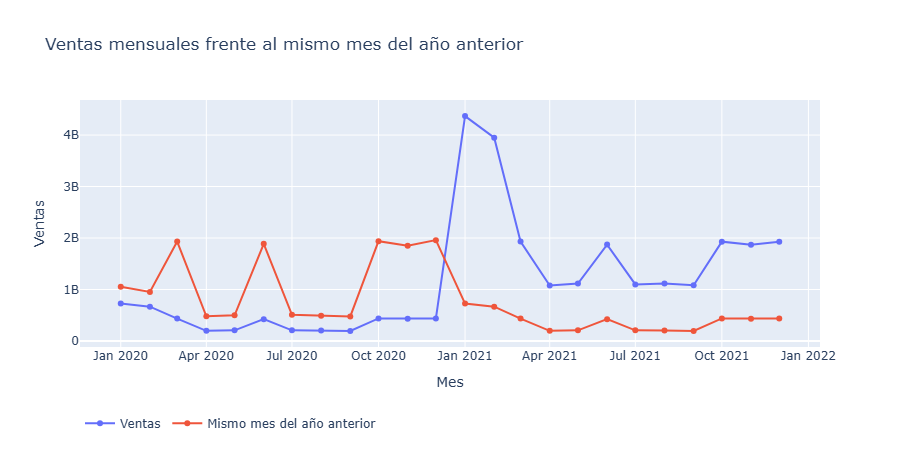

In [24]:
grafica = mensual[mensual["anio"] >= 2020].melt(
    id_vars="anio_mes", value_vars=["ventas", "ventas_mismo_mes_anio_anterior"],
    var_name="medida", value_name="importe",
).replace({"medida": {"ventas": "Ventas", "ventas_mismo_mes_anio_anterior": "Mismo mes del año anterior"}})
fig = px.line(
    grafica, x="anio_mes", y="importe", color="medida", markers=True,
    labels={"anio_mes": "Mes", "importe": "Ventas", "medida": ""},
    title="Ventas mensuales frente al mismo mes del año anterior",
)
fig.update_layout(legend={"orientation": "h", "y": -0.25})
fig.show()

## 8. Variación mensual y anual

Las variaciones combinan lo anterior: el valor actual, el valor del periodo de referencia y una división segura. Una sola función sirve para cualquier periodo:

In [25]:
def variacion(actual, anterior):
    # Variación relativa; en blanco si no hay periodo anterior o si vale cero
    return (actual - anterior) / anterior.where(anterior != 0)


tabla = mensual.assign(
    var_mensual=variacion(mensual["ventas"], mensual["ventas_mes_anterior"]),
    var_anual=variacion(mensual["ventas"], mensual["ventas_mismo_mes_anio_anterior"]),
)
seleccion = ["2019-01", "2019-12", "2020-01", "2020-02", "2020-03", "2021-01"]
columnas = ["anio_mes", "ventas", "ventas_mes_anterior", "var_mensual",
            "ventas_mismo_mes_anio_anterior", "var_anual", "ventas_ytd"]
ver(tabla[tabla["anio_mes"].isin(seleccion)][columnas], porcentajes=["var_mensual", "var_anual"])

anio_mes,ventas,ventas_mes_anterior,var_mensual,ventas_mismo_mes_anio_anterior,var_anual,ventas_ytd
2019-01,1 055 072 666,,,,,1 055 072 666
2019-12,1 958 766 078,1 851 126 376,5.81%,,,14 028 184 223
2020-01,726 241 507,1 958 766 078,-62.92%,1 055 072 666,-31.17%,726 241 507
2020-02,666 901 056,726 241 507,-8.17%,952 801 751,-30.01%,1 393 142 563
2020-03,434 689 279,666 901 056,-34.82%,1 931 341 497,-77.49%,1 827 831 842
2021-01,4 368 191 234,438 915 318,895.22%,726 241 507,501.48%,4 368 191 234


Tres detalles a observar:

- En 2019-01 no hay mes anterior ni año anterior dentro del calendario: la variación queda en blanco en lugar de dar error o infinito.
- El acumulado del año se reinicia en enero: 2020-01 vuelve a empezar desde 726 241 507.
- La ventana cruza el cambio de año sin problemas: el mes anterior a 2020-01 es 2019-12, y la caída es de −62.92 %. Enero de 2021 crece 895.22 % frente a diciembre de 2020 y 501.48 % frente a enero de 2020.

La misma función `variacion` sirve a nivel de año, sin cambiar una línea. Solo cambia la agrupación:

In [26]:
anual = practica.ventas_por(con, "anio").sort_values("anio")[["anio", "ventas_total"]].reset_index(drop=True)
anual["ventas_anio_anterior"] = anual["ventas_total"].shift(1)
anual["var_anual"] = variacion(anual["ventas_total"], anual["ventas_anio_anterior"])
ver(anual, porcentajes=["var_anual"])

anio,ventas_total,ventas_anio_anterior,var_anual
2019,14 028 184 223,,
2020,4 574 028 172,14 028 184 223,-67.39%
2021,23 338 746 430,4 574 028 172,410.24%


2020 cae un 67.39 % frente a 2019 y 2021 crece un 410.24 % frente a 2020. Esa es la ventaja de definir las medidas como funciones: el periodo lo decide la agrupación (el contexto) y la fórmula no necesita saber si está en un mes o en un año.

## 9. Las medidas en una app

La app [`m47-medidas-y-kpis-app.py`](m47-medidas-y-kpis-app.py) lleva estas medidas a un tablero de Streamlit. Se lanza desde la raíz del repositorio:

```bash
uv run streamlit run s08-dashboards/m47-medidas-y-kpis/m47-medidas-y-kpis-app.py
```

Tiene cuatro piezas:

**1. Conexión y columnas calculadas.** La conexión DuckDB se abre una sola vez con `@st.cache_resource`, y en ese momento se crea la vista con las columnas calculadas:

```python
@st.cache_resource
def conexion():
    con = practica.conectar()
    con.execute(f"""
        CREATE VIEW ventas_calculadas AS
        SELECT *,
               importe * {1 + IMPUESTO} AS ventas_con_impuestos,
               precio * {1 - DESCUENTO} AS precio_con_descuento
        FROM ventas_detalle
    """)
    return con
```

**2. El contexto de filtro en la barra lateral.** Un `st.multiselect` de países y un `st.select_slider` de meses producen un diccionario `filtros`, que se pasa tal cual a las medidas. El rango es de meses completos porque las medidas de tiempo trabajan sobre el calendario mensual. Las consultas van en funciones con `@st.cache_data` que reciben ese diccionario (con tuplas y fechas, que se pueden "hashear") y no la conexión:

```python
filtros = {"paises": tuple(paises), "desde": desde, "hasta": hasta}

@st.cache_data(max_entries=200, show_spinner=False)
def mensuales(filtros: dict, por: str | None = None) -> pd.DataFrame:
    return practica.ventas_mensuales(conexion(), por=por, **filtros)
```

**3. Pestaña "Resumen".** Tres tarjetas `st.metric`: ventas totales, venta promedio y las ventas del último mes del rango, con la variación frente al mes anterior en `delta`. Debajo, la línea mensual de ventas con la del mismo mes del año anterior.

```python
ultimo = serie.dropna(subset=["ventas"]).iloc[-1]
delta = None if pd.isna(ultimo["var_mensual"]) else f"{ultimo['var_mensual']:+.1%}"
col3.metric(f"Ventas de {nombre_mes(ultimo['anio_mes'])}", numero(ultimo["ventas"]), delta,
            delta_description="frente al mes anterior" if delta else None, border=True)
```

**4. Pestaña "Validación de medidas".** La tabla por país, año y mes de `ventas_mensuales(..., por="pais")` con `st.column_config.NumberColumn(format="localized")` para que los importes se lean con separador de miles, un botón `st.download_button` que descarga la tabla en CSV, un mapa `px.scatter_geo` con el tamaño de cada burbuja según la venta promedio (y las ventas totales en la información emergente) y las barras agrupadas de ventas con y sin impuestos por país.

Las dos pestañas se calculan en cada ejecución (`st.tabs` sin `on_change`): las consultas son agregados pequeños y quedan en caché, y así `AppTest` puede revisar el contenido de ambas.

`AppTest` ejecuta la app sin navegador. La celda siguiente la corre con los filtros por defecto, luego simula que el usuario elige Canadá y los meses de 2020 y comprueba que la tarjeta de ventas totales coincide con la medida de la sección 2:

In [27]:
from streamlit.testing.v1 import AppTest

app = AppTest.from_file(str(Path("m47-medidas-y-kpis-app.py").resolve()), default_timeout=60).run()
assert not app.exception
print("Pestañas:", [pestana.label for pestana in app.tabs])
for tarjeta in app.metric:
    print(f"  {tarjeta.label}: {tarjeta.value}  {tarjeta.proto.delta}")
print("Tabla de validación:", app.dataframe[0].value.shape, "| gráficos:", len(app.get("plotly_chart")))

app.multiselect(key="paises").set_value(["CANADA"])
app.select_slider(key="meses").set_value(("2020-01", "2020-12"))
app.run()
assert not app.exception
assert app.metric[0].value == f"{canada_2020['ventas_total']:,}".replace(",", " ")
print("\nCanadá, 2020:")
for tarjeta in app.metric:
    print(f"  {tarjeta.label}: {tarjeta.value}  {tarjeta.proto.delta}")

Pestañas: ['Resumen', 'Validación de medidas']
  Ventas totales: 41 940 958 825  
  Venta promedio: 27 979.29  
  Ventas de dic 2021: 1 928 765 134  +3.2%
Tabla de validación: (360, 9) | gráficos: 3



Canadá, 2020:
  Ventas totales: 856 197 372  
  Venta promedio: 17 295.87  
  Ventas de dic 2020: 81 969 824  +3.1%


La tarjeta de ventas totales de Canadá en 2020 muestra 856 197 372, la misma cifra de `practica.kpis` con ese contexto, y la tabla de validación tiene 360 filas (10 países × 36 meses) con los filtros por defecto.

## 10. Errores frecuentes

**Calcular la participación como una columna fija.** Si la participación se calcula una vez, dividiendo entre el total de toda la tabla, queda congelada: al filtrar por un país ya no suma 100 %.

In [28]:
pais_anio = practica.ventas_por(con, ["pais", "anio"])[["pais", "anio", "ventas_total"]]
pais_anio["participacion_fija"] = pais_anio["ventas_total"] / pais_anio["ventas_total"].sum()  # columna: una vez

canada = pais_anio[pais_anio["pais"] == "CANADA"].sort_values("anio").copy()
canada["participacion_medida"] = canada["ventas_total"] / canada["ventas_total"].sum()  # medida: con el filtro
print(f"Suma de la columna fija: {canada['participacion_fija'].sum():.2%} | suma de la medida: {canada['participacion_medida'].sum():.2%}")
ver(canada, porcentajes=["participacion_fija", "participacion_medida"])

Suma de la columna fija: 15.94% | suma de la medida: 100.00%


pais,anio,ventas_total,participacion_fija,participacion_medida
CANADA,2019,2 376 835 686,5.67%,35.56%
CANADA,2020,856 197 372,2.04%,12.81%
CANADA,2021,3 450 491 033,8.23%,51.63%


La columna fija responde "qué parte del total de todos los países aporta cada fila"; la medida, "qué parte de lo que estoy viendo". En un tablero con filtros, la segunda es casi siempre la pregunta correcta.

**Dividir sin protección.** Es tentador rellenar con 0 el mes que falta para "completar" la serie. Pero entonces la variación del mes siguiente divide entre cero:

In [29]:
rohan_cero = rohan_cal.assign(ventas=rohan_cal["ventas"].fillna(0))
anterior = rohan_cero["ventas"].shift(1)
rohan_cero["var_sin_proteccion"] = (rohan_cero["ventas"] - anterior) / anterior
rohan_cero["var_segura"] = variacion(rohan_cero["ventas"], anterior)
rohan_cero[rohan_cero["anio_mes"].between("2021-05", "2021-08")]

,anio,mes,anio_mes,ventas,var_sin_proteccion,var_segura
28,2021,5,2021-05,96786.0,3.349346,3.349346
29,2021,6,2021-06,0.0,-1.000000,-1.000000
30,2021,7,2021-07,116827.0,inf,NaN
31,2021,8,2021-08,95071.0,-0.186224,-0.186224


La variación de 2021-07 sin protección es `inf`; con `variacion` (que usa `where`) queda en blanco. Y la de 2021-06 es −100 %, cierta pero engañosa si el mes en realidad no tuvo actividad registrada. Rellenar con 0 o dejar `NaN` es una decisión de negocio, no un detalle técnico.

**Usar las fechas de los hechos en lugar del calendario.** Sin la rejilla del calendario, `shift(1)` toma "la fila de arriba", que no siempre es el mes anterior:

In [30]:
sin_calendario = rohan.assign(
    mes_anterior=rohan["ventas"].shift(1),
    mes_anterior_de=rohan["anio_mes"].shift(1),
    anio_anterior_de=rohan["anio_mes"].shift(12),
)
sin_calendario[sin_calendario["anio_mes"].between("2021-05", "2021-08")]

,anio,mes,anio_mes,ventas,mes_anterior,mes_anterior_de,anio_anterior_de
28,2021,5,2021-05,96786.0,22253.0,2021-04,2020-05
29,2021,7,2021-07,116827.0,96786.0,2021-05,2020-06
30,2021,8,2021-08,95071.0,116827.0,2021-07,2020-07


Para 2021-07, el "mes anterior" resulta ser mayo de 2021 y el "mismo mes del año anterior", junio de 2020: todo lo que viene después del hueco queda desplazado, sin ningún aviso. Con `rohan_cal` (sección 6) el mes anterior de 2021-07 es junio, en blanco, y el del año anterior es julio de 2020.

**Ordenar los meses alfabéticamente.** `nombre_mes` es texto, y el texto se ordena letra por letra:

In [31]:
por_mes = con.execute("""
    SELECT nombre_mes, CAST(sum(importe) AS BIGINT) AS ventas
    FROM ventas_detalle JOIN calendario USING (fecha)
    GROUP BY nombre_mes
""").df()
print("Alfabético:", por_mes.sort_values("nombre_mes")["nombre_mes"].tolist())

por_mes["nombre_mes"] = pd.Categorical(por_mes["nombre_mes"], categories=practica.NOMBRES_MES, ordered=True)
print("Calendario:", por_mes.sort_values("nombre_mes")["nombre_mes"].tolist())

Alfabético: ['abr', 'ago', 'dic', 'ene', 'feb', 'jul', 'jun', 'mar', 'may', 'nov', 'oct', 'sep']
Calendario: ['ene', 'feb', 'mar', 'abr', 'may', 'jun', 'jul', 'ago', 'sep', 'oct', 'nov', 'dic']


Se corrige convirtiendo la columna en una categoría ordenada (o ordenando por el número de mes). En Plotly, el orden de un eje de texto se fija con `category_orders={"nombre_mes": practica.NOMBRES_MES}`.

**Multiplicar enteros pequeños.** En el modelo, `cantidad` y `precio` son enteros de 16 bits (de −32 768 a 32 767). DuckDB detecta el desbordamiento y falla; pandas, en cambio, **da la vuelta en silencio** y devuelve importes negativos:

In [32]:
try:
    con.execute("SELECT sum(cantidad * precio) FROM ventas").fetchone()
except Exception as error:
    print("DuckDB:", type(error).__name__, "->", str(error).splitlines()[0])

producto_16 = hechos["cantidad"] * hechos["precio"]
print("pandas:", producto_16.dtype, "| importes negativos:", (producto_16 < 0).sum(), "| mínimo:", producto_16.min())
print(f"Suma con int16: {producto_16.sum():,} | suma correcta: {correcto:,}".replace(",", " "))

DuckDB: OutOfRangeException -> Out of Range Error: Overflow in multiplication of INT16 (229 * 260)!
pandas: int16 | importes negativos: 272528 | mínimo: -32768
Suma con int16: 7 375 109 737 | suma correcta: 41 940 958 825


Por eso la vista `ventas` de `practica.conectar()` calcula `importe` con `CAST(cantidad AS BIGINT) * precio`, y en pandas hay que convertir antes de multiplicar (`astype("int64")`).

**Reemplazar un filtro cuando se quería combinarlo.** `filtros | {"categorias": [...]}` sustituye el filtro de categoría que venga del tablero; si el usuario había elegido otra categoría, la medida la ignora. Cuando se quiere la intersección, hay que calcularla explícitamente, como `ventas_furniture_combinado` en la sección 4.

## 11. Ejercicio

Con el modelo de ventas y la tabla `calendario`:

1. Calcula las ventas del **trimestre anterior** con una función de ventana sobre la rejilla de trimestres del calendario.
2. Calcula la **variación trimestral** con una CTE y una división segura.
3. Calcula la **participación en el año**: qué parte de las ventas del año aporta cada trimestre.
4. Calcula las **ventas acumuladas del trimestre** en una tabla por mes (en una tabla por trimestre coincidirían con las ventas).
5. Comprueba los resultados de 2020: el trimestre anterior a 2020-T1 debe ser 2019-T4 y las cuatro participaciones deben sumar 100 %.

### Solución

In [33]:
trimestral = con.execute("""
    WITH trimestres AS (
        SELECT DISTINCT anio, trimestre FROM calendario
    ),
    base AS (
        SELECT anio, trimestre, sum(importe) AS ventas
        FROM ventas_detalle
        GROUP BY ALL
    ),
    medidas AS (
        SELECT t.anio, t.trimestre, b.ventas,
               lag(b.ventas) OVER (ORDER BY t.anio, t.trimestre) AS ventas_trimestre_anterior,
               sum(b.ventas) OVER (PARTITION BY t.anio) AS ventas_anio
        FROM trimestres t
        LEFT JOIN base b USING (anio, trimestre)
    )
    SELECT anio, trimestre,
           CAST(ventas AS DOUBLE) AS ventas,
           CAST(ventas_trimestre_anterior AS DOUBLE) AS ventas_trimestre_anterior,
           (ventas - ventas_trimestre_anterior) / NULLIF(ventas_trimestre_anterior, 0) AS var_trimestral,
           ventas / NULLIF(ventas_anio, 0) AS participacion_anio
    FROM medidas
    ORDER BY anio, trimestre
""").df()

t2020 = trimestral[trimestral["anio"] == 2020]
print(f"Participaciones de 2020: {t2020['participacion_anio'].sum():.2%}")
ver(t2020, porcentajes=["var_trimestral", "participacion_anio"])

Participaciones de 2020: 100.00%

anio,trimestre,ventas,ventas_trimestre_anterior,var_trimestral,participacion_anio
2020,1,1 827 831 842,5 747 580 818,-68.20%,39.96%
2020,2,827 844 344,1 827 831 842,-54.71%,18.10%
2020,3,608 272 193,827 844 344,-26.52%,13.30%
2020,4,1 310 079 793,608 272 193,115.38%,28.64%


`PARTITION BY t.anio` sin `ORDER BY` hace que el denominador sea el total del año de cada fila, que es lo que en una herramienta de BI haría `ALLEXCEPT(Calendario, Calendario[Año])`. El acumulado del trimestre se ve en una tabla por mes; en pandas basta con agrupar por año y trimestre:

In [34]:
meses_2020 = mensual_pd.merge(calendario[["anio", "mes", "trimestre"]].drop_duplicates(), on=["anio", "mes"])
meses_2020 = meses_2020[meses_2020["anio"] == 2020][["anio", "trimestre", "mes", "ventas"]].copy()
meses_2020["ventas_qtd"] = meses_2020.groupby(["anio", "trimestre"])["ventas"].cumsum()

# El último mes de cada trimestre acumula exactamente las ventas del trimestre
cierres = meses_2020.groupby("trimestre")["ventas_qtd"].last().to_numpy()
assert np.allclose(cierres, t2020["ventas"].to_numpy())
ver(meses_2020)

anio,trimestre,mes,ventas,ventas_qtd
2020,1,1,726 241 507,726 241 507
2020,1,2,666 901 056,1 393 142 563
2020,1,3,434 689 279,1 827 831 842
2020,2,4,197 289 959,197 289 959
2020,2,5,206 886 231,404 176 190
2020,2,6,423 668 154,827 844 344
2020,3,7,206 706 925,206 706 925
2020,3,8,205 713 422,412 420 347
2020,3,9,195 851 846,608 272 193
2020,4,10,438 464 091,438 464 091


In [35]:
t2021 = trimestral[(trimestral["anio"] == 2021) & (trimestral["trimestre"] == 1)].iloc[0]
print(f"2021-T1: {t2021['ventas']:,.0f} frente a {t2021['ventas_trimestre_anterior']:,.0f} -> {t2021['var_trimestral']:.2%}".replace(",", " "))

2021-T1: 10 248 999 518 frente a 1 310 079 793 -> 682.32%


El trimestre anterior a 2020-T1 es 2019-T4 (5 747 580 818): la ventana cruza el cambio de año porque ordena por `anio, trimestre` sobre la rejilla completa. 2020-T1 cae un 68.20 % y aporta el 39.96 % del año; las cuatro participaciones suman 100 %. En 2021-T1 la variación trimestral es 682.32 % (10 248 999 518 frente a 1 310 079 793). En la tabla por mes, el acumulado del trimestre vuelve a empezar en enero, abril, julio y octubre, y el último mes de cada trimestre coincide con las ventas del trimestre.

## Resumen

- Las columnas calculadas se evalúan por fila y sirven para agrupar o filtrar; las medidas son funciones que agregan dentro de un contexto de filtro y se adaptan a cualquier agrupación.
- El contexto de filtro, en código, son los argumentos de la medida y el `WHERE`; el `GROUP BY` hace de filas del tablero.
- La suma de productos no es el producto de sumas: `sum(cantidad * precio)` y `sum(cantidad) * avg(precio)` difieren en un 6.6 %.
- Cambiar el contexto es cambiar el diccionario de filtros: reemplazar, intersectar o quitar una clave. En SQL, `sum(...) OVER ()` da el total para las participaciones.
- `NULLIF`, `Series.where` y `np.divide(where=)` evitan los infinitos; las CTE y las variables hacen legibles los cálculos.
- Las medidas de tiempo necesitan una rejilla de calendario completa; sobre ella, `lag`/`shift`, `lag(..., 12)`/`shift(12)` y `sum() OVER (PARTITION BY anio ORDER BY mes)` resuelven mes anterior, año anterior y acumulado del año.

En el **Módulo 48** el tablero se vuelve interactivo: filtros cruzados entre gráficos, exploración en profundidad y detalles bajo demanda en Streamlit.